# Skin disease classification, step by step

We will clean the data, choose 20 diagnoses, split the images, and train ResNet18.
Pandas handles the tables. Scikit-learn handles splitting and scores. PyTorch trains
the neural network. Run the cells from top to bottom.

Keep these files beside the notebook:
- `Derm1M_v2_pretrain.csv`
- `Derm1M_v2_validation.csv`
- `image_color_audit.csv` from the completed image check

The extracted image folders (`IIYI`, `youtube`, `pubmed`, and the others) should also
be beside the notebook. The CSV already contains filenames such as `IIYI/26549_2.png`.
The local files have been arranged this way. For Colab, use the same arrangement.

The official CSV has no diagnosis labels, so we can export its predictions but
cannot calculate its accuracy. Our validation scores are internal experiment scores.


## 1. Import the libraries

These are the tools used below. There are no external Python helper files.


In [64]:
import io
import re
import time
import random
import hashlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, ImageOps, ImageCms
from tqdm.auto import tqdm

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.models import resnet18, ResNet18_Weights

## Optional: log in to Hugging Face

Set `login_to_hugging_face=True` below and run the cell to sign in. Create a
[Hugging Face access token](https://huggingface.co/settings/tokens) and paste it
into the hidden input when prompted; do not paste it into the cell's code.
A read token is sufficient for downloads; uploading models requires write access.

This uses `huggingface_hub`, already included in `requirements.txt`. The library
caches your login in the current machine or runtime's Hugging Face cache, rather
than saving the token in the notebook or adding it to Git credentials.
The current ResNet18 training uses local data and Torchvision weights, so login
is optional. Signing in does not download data or upload your model automatically.
See the [authentication guide](https://huggingface.co/docs/huggingface_hub/main/package_reference/authentication).


In [65]:
login_to_hugging_face = False

if login_to_hugging_face:
    from getpass import getpass
    from huggingface_hub import login

    hf_token = getpass("Hugging Face access token (hidden; leave blank to skip): ").strip()
    try:
        if hf_token:
            login(token=hf_token, add_to_git_credential=False)
        else:
            print("Hugging Face login skipped.")
    finally:
        del hf_token


## 2. Choose the settings

The full dataset for these 20 diagnoses has about 36,777 training images: 1,150 batches
at batch size 32. Set `fast_mode=True` for at most 300 images per class each epoch
(about 188 batches). Fast mode cycles through each class instead of repeating one sample; validation
stays fixed. Small classes repeat sooner, and early stopping can end before all
training images have been used.

`reuse_image_checks=True` reads the completed audit CSV. Set it to False if you
replace or edit the images, or if that CSV is unavailable. Weight decay 0.001 is an
experiment to reduce overfitting. Use a new `run_name` for each training experiment.


In [66]:
run_name = "dropout_040_run"
resume_training = False  # Set True to continue from this run's best saved checkpoint.
fast_mode = False
images_per_class = 300
validation_images_per_class = 50
reuse_image_checks = True
run_feature_baseline = False
predict_official_images = True

batch_size = 32
number_of_epochs = 20
warmup_epochs = 2
early_stopping_patience = 3
learning_rate_patience = 1
minimum_improvement = 0.0001
dropout_rate = 0.40
weight_decay = 0.001
seed = 42

selected_diseases = [
    "acne", "basal cell carcinoma", "bullous pemphigoid", "cellulitis",
    "eczema", "folliculitis", "herpes zoster", "impetigo", "lichen planus",
    "melanoma", "molluscum contagiosum", "nevus", "pityriasis rosea",
    "psoriasis", "rosacea", "scabies", "seborrheic keratoses",
    "squamous cell carcinoma", "urticaria", "vitiligo"
]

random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)

if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
print("Using:", device)

Using: mps


## 3. Read the two CSV files

Load each file directly by its filename and look at its columns.


In [67]:
raw_data = pd.read_csv("Derm1M_v2_pretrain.csv", low_memory=False)
official_data = pd.read_csv("Derm1M_v2_validation.csv", low_memory=False)
print("Training rows:", len(raw_data))
print("Official rows:", len(official_data))
print(raw_data.columns.tolist())
raw_data.head()

Training rows: 413210
Official rows: 9806
['filename', 'caption', 'truncated_caption', 'source', 'source_type', 'disease_label', 'hierarchical_disease_label', 'skin_concept', 'body_location', 'symptoms', 'age', 'gender']


,filename,caption,truncated_caption,source,source_type,disease_label,hierarchical_disease_label,skin_concept,body_location,symptoms,age,gender
0,IIYI/26549_2.png,"Male, 15 years old, has been experiencing spon...","Male, 15 years old, has been experiencing spon...",IIYI_chinese,forum,epidermolysis bullosa,"hereditary, epidermolysis bullosa","flat, scar",No body location information,No symptom information,15,No gender information
1,youtube/ykOs8g7zjDc_frame_1135_15.jpg,This image discusses natural treatments and ho...,This image discusses natural treatments and ho...,youtube,edu,no definitive diagnosis,no definitive diagnosis,No visual concepts,lips,No symptom information,No age information,No gender information
2,youtube/8wBKdJ1JWHQ_frame_6758_0_0.jpg,"This image shows various skin diseases, includ...","This image shows various skin diseases, includ...",youtube,edu,"erythrasma, pitriasis versicolor, tenia capiti...","erythrasma, pitriasis versicolor, tenia capiti...","yellow, red, blue",No body location information,No symptom information,No age information,No gender information
3,pubmed/b9_2b_PMC4886598_IDOJ_7_203_g001.png,Bosellated and ulcerated swelling on the face,Bosellated and ulcerated swelling on the face,pubmed_english,knowledge,ulcer,"reaction patterns and descriptive terms, ulcer...","ulcer, ulcerated",face,No symptom information,No age information,No gender information
4,youtube/3bLlU_wTljA_frame_32617_3.jpg,This image describes dysplastic nevus syndrome...,This image describes dysplastic nevus syndrome...,youtube,edu,nevus,nevus,No visual concepts,No body location information,No symptom information,No age information,No gender information


## 4. Clean the labels

Keep one clear diagnosis per image. Do not merge similar disease names automatically.
Remove conflicting labels for the same filename and captions that explicitly describe
an uncertain diagnosis. This text screen can reject valid examples; it does not prove
that the remaining labels are medically correct. Captions are never model inputs.


In [68]:
def clean_label(value):
    labels = [word.strip() for word in value.split(",")]
    if len(set(labels)) != 1:
        return None
    if labels[0] in ["", "nan", "none", "unknown", "no definitive diagnosis"]:
        return None
    return labels[0]


data = raw_data[["filename", "disease_label", "source", "caption"]].fillna("").copy()
data["filename"] = data["filename"].str.strip().str.replace("\\", "/", regex=False)
data["disease_label"] = data["disease_label"].str.lower().str.split().str.join(" ")
data["label"] = data["disease_label"].apply(clean_label)

label_counts = data.groupby("filename")["disease_label"].nunique()
conflicting_files = label_counts[label_counts > 1].index
data = data[~data["filename"].isin(conflicting_files)]
data = data.dropna(subset=["label"])
data = data[data["filename"] != ""]
data = data.drop_duplicates(subset="filename")

uncertain_words = r"differential diagnos(?:is|es)|differential includes|suspected|possible diagnosis|uncertain diagnosis|rule out"
uncertain = data["caption"].str.contains(r"\b(?:" + uncertain_words + r")\b", case=False, regex=True)
data = data[~uncertain]
data = data[["filename", "label", "source"]].reset_index(drop=True)
print("Single-label images after cleaning:", len(data))

Single-label images after cleaning: 264453


## 5. Keep related images together

Images from the same video, article, post, or textbook page should stay in the same
split. These groups are useful clues, but they cannot guarantee different patients.
Also exclude training groups that occur in the official data.


In [69]:
official_groups = official_data[["filename", "source"]].copy()

for table in [data, official_groups]:
    names = table["filename"].str.split("/").str[-1]
    stems = names.str.rsplit(".", n=1).str[0]
    table["group"] = "image:" + names

    youtube_rows = table["source"].eq("youtube")
    table.loc[youtube_rows, "group"] = "youtube:" + stems[youtube_rows].str.split("_frame_").str[0]

    article_ids = stems.str.extract(r"(PMC\d+)", flags=re.IGNORECASE, expand=False)
    table.loc[article_ids.notna(), "group"] = "pubmed:" + article_ids.dropna().str.lower()

    for website in ["iiyi", "reddit", "twitter"]:
        website_rows = table["source"].str.lower().str.startswith(website)
        table.loc[website_rows, "group"] = website + ":" + stems[website_rows].str.split("_").str[0]

    pages = stems.str.extract(r"^(.+?_\d{5})(?:_.*)?$", expand=False)
    textbook_rows = table["source"].str.startswith("textbook") & pages.notna()
    table.loc[textbook_rows, "group"] = "book:" + pages[textbook_rows]

data = data[~data["group"].isin(official_groups["group"])].reset_index(drop=True)
print("Images after separating official groups:", len(data))

Images after separating official groups: 186665


## 6. Read images in a consistent color space

We need one image-reading function because training, validation, and prediction must
handle colors in the same way. It corrects rotation, converts valid color profiles to
sRGB, and puts transparent pixels on white. Untagged RGB images are assumed to be
sRGB. Unsupported color cases raise an error for review.


In [70]:
def load_image(filename):
    with Image.open(filename) as original:
        if getattr(original, "n_frames", 1) != 1:
            raise ValueError("This image has multiple frames.")
        image = ImageOps.exif_transpose(original)
        if image.mode not in ["1", "L", "LA", "P", "RGB", "RGBA", "CMYK", "LAB", "YCbCr"]:
            raise ValueError("This image mode needs review: " + image.mode)

        alpha = None
        if "A" in image.getbands() or "transparency" in image.info:
            rgba_image = image.convert("RGBA")
            alpha = rgba_image.getchannel("A")
        color_image = rgba_image if alpha is not None else image
        profile_bytes = image.info.get("icc_profile")

        if profile_bytes:
            profile = ImageCms.ImageCmsProfile(io.BytesIO(profile_bytes))
            profile_space = profile.profile.xcolor_space.strip()
            if profile_space == "RGB" and image.mode not in ["CMYK", "LAB"]:
                color_image = color_image.convert("RGB")
            elif profile_space == "GRAY" and image.mode in ["1", "L", "LA"]:
                color_image = image.convert("L")
            elif not ((profile_space == "CMYK" and image.mode == "CMYK") or
                      (profile_space == "Lab" and image.mode == "LAB")):
                raise ValueError("The image mode and color profile do not match.")
            color_image = ImageCms.profileToProfile(
                color_image, profile, ImageCms.createProfile("sRGB"), outputMode="RGB")
        else:
            exif = image.getexif()
            color_tag = exif.get_ifd(34665).get(40961, exif.get(40961))
            if image.mode in ["CMYK", "LAB"] or color_tag == 2:
                raise ValueError("This image needs a color profile.")
            color_image = color_image.convert("RGB")

        if alpha is not None:
            color_image = Image.composite(color_image, Image.new("RGB", image.size, "white"), alpha)
        return color_image

## 7. Check image quality and remove exact copies

The existing audit CSV contains image sizes, modes, color decisions, and pixel
fingerprints. Reuse it for unchanged images. The alternative loop below does the
checks inside this notebook, which takes longer.

Check duplicates across all remaining labels before selecting the 20 diagnoses.
Remove tiny/unreadable images, conflicting copies, and copies of official images.
Keep one representative when duplicate pixels have the same label. Fingerprints
catch exact displayed copies; they do not catch every cropped or compressed copy.


In [71]:
if reuse_image_checks:
    image_checks = pd.read_csv("image_color_audit.csv", keep_default_na=False)
else:
    filenames = pd.concat([data["filename"], official_data["filename"]]).drop_duplicates()
    checked_images = []
    for filename in tqdm(filenames, desc="Checking images"):
        result = {"filename": filename, "status": "ok", "error": "", "width": 0,
                  "height": 0, "original_mode": "", "pixel_hash": ""}
        try:
            with Image.open(filename) as original:
                result["original_mode"] = original.mode
            image = load_image(filename)
            result["width"], result["height"] = image.size
            result["pixel_hash"] = hashlib.sha256(str(image.size).encode() + image.tobytes()).hexdigest()
        except (OSError, ValueError, TypeError, SyntaxError, ImageCms.PyCMSError, Image.DecompressionBombError) as error:
            result["status"] = "needs_review"
            result["error"] = str(error)
        checked_images.append(result)
    image_checks = pd.DataFrame(checked_images)
    image_checks.to_csv(run_name + "_image_checks.csv", index=False)

print("Original image modes:")
print(image_checks["original_mode"].value_counts())
image_checks = image_checks[["filename", "status", "width", "height", "pixel_hash"]]
data = data.merge(image_checks, on="filename", how="left", validate="one_to_one")
official_checks = official_data[["filename"]].merge(image_checks, on="filename", how="left", validate="one_to_one")
if data["status"].isna().any() or official_checks["status"].isna().any():
    raise ValueError("The audit is incomplete. Set reuse_image_checks=False and rerun from the CSV cell.")

data = data[(data["status"] == "ok") & (data["width"] >= 64) & (data["height"] >= 64)]
labels_per_image = data.groupby("pixel_hash")["label"].nunique()
conflicting_hashes = labels_per_image[labels_per_image > 1].index
official_hashes = official_checks.loc[official_checks["status"] == "ok", "pixel_hash"]
data = data[~data["pixel_hash"].isin(conflicting_hashes)]
data = data[~data["pixel_hash"].isin(official_hashes)]
data = data.sort_values("filename").drop_duplicates("pixel_hash").sort_index().reset_index(drop=True)
print("Cleaned single-label images:", len(data))
print("Official images needing review:", (official_checks["status"] != "ok").sum())

Original image modes:
original_mode
RGB     422203
RGBA       675
L           85
P           53
Name: count, dtype: int64
Cleaned single-label images: 183665
Official images needing review: 0


## 8. Select the 20 diagnoses

Check how many images, groups, and sources each diagnosis has before training.


In [72]:
data = data[data["label"].isin(selected_diseases)].reset_index(drop=True)
class_names = sorted(selected_diseases)
label_numbers = {name: number for number, name in enumerate(class_names)}

class_counts = pd.DataFrame({
    "images": data.groupby("label").size(),
    "groups": data.groupby("label")["group"].nunique(),
    "sources": data.groupby("label")["source"].nunique()
}).reindex(class_names).fillna(0)
if (class_counts["images"] < 150).any() or (class_counts["groups"] < 50).any() or (class_counts["sources"] < 2).any():
    raise ValueError("Some diagnoses have too little usable data. Check class_counts before training.")
class_counts

,images,groups,sources
label,,,
acne,1593,852,10
basal cell carcinoma,2505,1875,11
bullous pemphigoid,655,383,9
cellulitis,582,352,10
eczema,5035,3680,10
folliculitis,893,616,10
herpes zoster,1425,761,10
impetigo,721,400,10
lichen planus,1335,674,9


## 9. Split training and validation

Make the group split before taking a smaller sample. The full validation set stays
the same in both modes. Fast mode uses a fixed sample of it during training and
reports the full set afterward. That full report still includes model-selection data.


In [73]:
splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=seed)
train_indices, validation_indices = next(splitter.split(data, data["label"], data["group"]))
training_pool = data.iloc[train_indices].reset_index(drop=True)
full_validation_data = data.iloc[validation_indices].reset_index(drop=True)

assert not set(training_pool["group"]) & set(full_validation_data["group"])
assert not set(training_pool["pixel_hash"]) & set(full_validation_data["pixel_hash"])
assert set(training_pool["label"]) == set(class_names)
assert set(full_validation_data["label"]) == set(class_names)

training_data = training_pool.copy()
validation_data = full_validation_data.copy()
if fast_mode:
    training_parts = []
    validation_parts = []
    for disease in class_names:
        disease_train = training_pool[training_pool["label"] == disease]
        disease_validation = full_validation_data[full_validation_data["label"] == disease]
        disease_train = disease_train.sample(frac=1, random_state=seed)
        # Put first images from each group before second images.
        disease_train["image_number"] = disease_train.groupby("group").cumcount()
        disease_train = disease_train.sort_values("image_number", kind="stable").drop(columns="image_number")
        training_parts.append(disease_train.head(images_per_class))
        validation_parts.append(disease_validation.sample(n=min(validation_images_per_class, len(disease_validation)), random_state=seed))
    training_data = pd.concat(training_parts).reset_index(drop=True)
    validation_data = pd.concat(validation_parts).reset_index(drop=True)

print("Training images per epoch:", len(training_data), "out of", len(training_pool))
print("Validation images per epoch:", len(validation_data), "out of", len(full_validation_data))


Training images per epoch: 36777 out of 36777
Validation images per epoch: 9195 out of 9195


## 10. Prepare the images

Resize with padding so the whole photograph stays visible. Use mild augmentation
only for training. The ImageNet mean and standard deviation match the pretrained
network. Avoid strong hue changes because image color can matter.


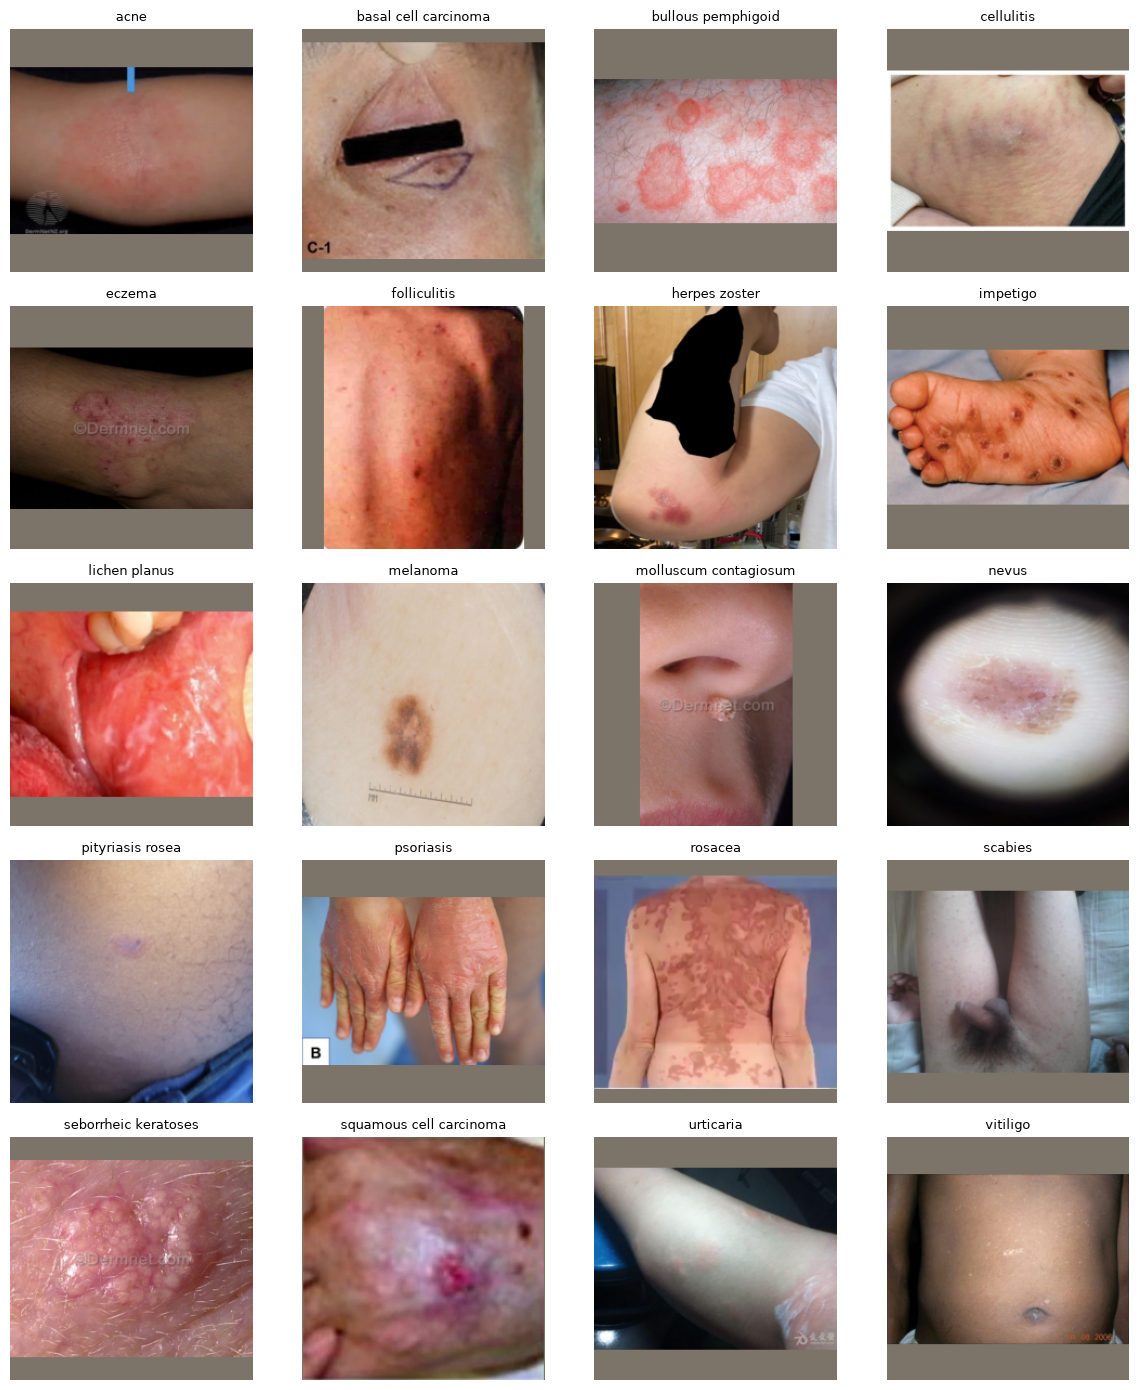

In [74]:
def resize_image(image):
    return ImageOps.pad(image, (224, 224), method=Image.Resampling.BILINEAR, color=(124, 116, 104))


normalization = transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
training_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10, interpolation=transforms.InterpolationMode.BILINEAR,
                              expand=True, fill=(124, 116, 104)),
    transforms.ColorJitter(brightness=0.1, contrast=0.1),
    resize_image,
    transforms.ToTensor(),
    normalization
])
validation_transform = transforms.Compose([resize_image, transforms.ToTensor(), normalization])

examples = training_data.groupby("label").sample(n=1, random_state=seed)
figure, axes = plt.subplots(5, 4, figsize=(12, 14))
for axis, row in zip(axes.flat, examples.itertuples()):
    axis.imshow(resize_image(load_image(row.filename)))
    axis.set_title(row.label, fontsize=9)
    axis.axis("off")
plt.tight_layout()
plt.show()

## 11. Put images into batches

PyTorch needs a small Dataset class to load images one at a time. It returns the
image and its class number. A DataLoader combines these into batches. Zero worker
processes keeps this easy to run in local notebooks.


In [75]:
class SkinDataset(Dataset):
    def __init__(self, rows, transform):
        self.rows = rows.reset_index(drop=True)
        self.transform = transform
        self.label_numbers = label_numbers.copy()

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, index):
        row = self.rows.iloc[index]
        image = self.transform(load_image(row["filename"]))
        label = self.label_numbers[row["label"]]
        return image, label


validation_loader = DataLoader(SkinDataset(validation_data, validation_transform), batch_size=batch_size)
full_validation_loader = DataLoader(SkinDataset(full_validation_data, validation_transform), batch_size=batch_size)
print("Training batches per epoch:", (len(training_data) + batch_size - 1) // batch_size)
print("Validation batches per epoch:", len(validation_loader))

Training batches per epoch: 1150
Validation batches per epoch: 288


## 12. Optional: try simple feature engineering

This baseline uses 12 global color and texture measurements. Fit the scaler on
training images only. These features include the background and are not a diagnosis
rule. The CNN learns its own features separately. Enable `run_feature_baseline` to
run this comparison; it uses the first training sample.


In [76]:
def image_features(image):
    pixels = np.asarray(image.resize((64, 64)), dtype=np.float32) / 255.0
    gray = pixels[:, :, 0] * 0.299 + pixels[:, :, 1] * 0.587 + pixels[:, :, 2] * 0.114
    saturation = (pixels.max(axis=2) - pixels.min(axis=2)) / np.maximum(pixels.max(axis=2), 0.000001)
    return np.concatenate([
        pixels.mean(axis=(0, 1)), pixels.std(axis=(0, 1)),
        [gray.mean(), gray.std(), saturation.mean(), saturation.std(),
         np.abs(np.diff(gray, axis=0)).mean(), np.abs(np.diff(gray, axis=1)).mean()]
    ])


if run_feature_baseline:
    training_features = [image_features(load_image(name)) for name in tqdm(training_data["filename"])]
    validation_features = [image_features(load_image(name)) for name in tqdm(validation_data["filename"])]
    scaler = StandardScaler()
    training_features = scaler.fit_transform(training_features)
    validation_features = scaler.transform(validation_features)
    baseline = LogisticRegression(max_iter=1000, class_weight="balanced")
    baseline.fit(training_features, training_data["label"])
    baseline_predictions = baseline.predict(validation_features)
    print("Feature baseline accuracy:", accuracy_score(validation_data["label"], baseline_predictions))
    print("Feature baseline macro F1:", f1_score(validation_data["label"], baseline_predictions, labels=class_names, average="macro", zero_division=0))

## 13. Write the validation step

This function is reused after each epoch and for the final report. It turns off
training behavior and gradients, then returns the true classes, predicted classes,
and average loss. Validation uses ordinary, unweighted cross-entropy.


In [77]:
def evaluate_model(model, loader):
    model.eval()
    actual_labels = []
    predicted_labels = []
    total_loss = 0.0
    with torch.no_grad():
        for images, labels in tqdm(loader, desc="Validation", unit="batch", leave=False):
            images = images.to(device)
            labels = labels.to(device)
            outputs = model(images)
            total_loss += nn.functional.cross_entropy(outputs, labels, reduction="sum").item()
            actual_labels.extend(labels.cpu().tolist())
            predicted_labels.extend(outputs.argmax(dim=1).cpu().tolist())
    return actual_labels, predicted_labels, total_loss / len(actual_labels)

## 14. Build or resume the model and train it

The classifier learns first. After warmup, the final ResNet block also learns.
Weight decay and dropout provide regularization; early layers stay frozen.
Training accuracy includes dropout and augmentation, while validation accuracy does not.

For a new experiment, leave `resume_training=False` and choose an unused `run_name`.
To continue an existing run, keep its `run_name`, set `resume_training=True` in the
settings cell, and restart the kernel and run from the beginning. The epoch limit
is a total: `number_of_epochs=20` continues up to epoch 20, not 20 extra epochs.

Resume loads the **best saved checkpoint**, which may be earlier than the last
logged epoch. It checks that the classes, dropout, weight decay, and saved data split
match. Existing model and history files are copied to timestamped backups before
training continues, and history after the saved checkpoint is replaced by the new branch.

Older checkpoints contain only weights and model metadata. For those, AdamW's
internal state and the scheduler/early-stopping counters restart; the learning rates
are recovered from the history at the checkpoint epoch. New checkpoints also save
optimizer and scheduler states and the training phase settings. Random generators
are reseeded, so this resumes learning without promising an identical uninterrupted run.


In [ ]:
from pathlib import Path
from shutil import copy2
from datetime import datetime, timezone

model_filename = run_name + "_model.pth"
history_filename = run_name + "_history.csv"
resume_checkpoint = None
start_epoch = 0
history = []

if not 0 <= warmup_epochs < number_of_epochs:
    raise ValueError("warmup_epochs must be smaller than number_of_epochs.")
if learning_rate_patience < 0 or early_stopping_patience < learning_rate_patience + 2:
    raise ValueError("Early stopping must allow an epoch after the learning rate decreases.")

if resume_training:
    if not Path(model_filename).is_file():
        raise ValueError("No saved model for this run. Set resume_training=False to start it.")
    resume_checkpoint = torch.load(model_filename, map_location="cpu", weights_only=True)
    if resume_checkpoint["classes"] != class_names:
        raise ValueError("Saved classes differ. Use the original classes or choose a new run_name.")
    for setting, value in [("dropout", dropout_rate), ("weight_decay", weight_decay),
                           ("warmup_epochs", warmup_epochs), ("fast_mode", fast_mode),
                           ("images_per_class", images_per_class), ("batch_size", batch_size),
                           ("seed", seed), ("learning_rate_patience", learning_rate_patience),
                           ("early_stopping_patience", early_stopping_patience),
                           ("minimum_improvement", minimum_improvement)]:
        if setting in resume_checkpoint and resume_checkpoint[setting] != value:
            raise ValueError("Resume requires the saved " + setting + ". Use a new run_name to change it.")
    start_epoch = int(resume_checkpoint["epoch"])
    if start_epoch >= number_of_epochs:
        raise ValueError("Increase number_of_epochs above the saved checkpoint epoch to continue.")
    if not Path(history_filename).is_file():
        raise ValueError("Resume needs this run's history CSV to preserve its training history.")
    saved_history = pd.read_csv(history_filename)
    saved_history = saved_history[saved_history["epoch"] <= start_epoch]
    if saved_history["epoch"].tolist() != list(range(1, start_epoch + 1)):
        raise ValueError("The history CSV does not match the saved checkpoint epochs.")
    if not np.isclose(saved_history.iloc[-1]["macro_f1"], resume_checkpoint["macro_f1"]):
        raise ValueError("The history CSV does not match the saved checkpoint score.")
    history = saved_history.to_dict("records")
    for suffix, current_rows in [("_training.csv", training_pool),
                                  ("_validation.csv", full_validation_data)]:
        manifest = Path(run_name + suffix)
        if not manifest.is_file():
            raise ValueError("Resume needs the original split file: " + str(manifest))
        saved_rows = pd.read_csv(manifest)
        columns = ["filename", "label", "group", "pixel_hash"]
        # These fields are text; CSV loading may infer a different Pandas text dtype.
        saved_rows = saved_rows[columns].astype("string").sort_values("filename").reset_index(drop=True)
        current_rows = current_rows[columns].astype("string").sort_values("filename").reset_index(drop=True)
        if not saved_rows.equals(current_rows):
            raise ValueError("The data split changed. Restore it or use a new run_name.")
    print("Continuing from best checkpoint at epoch", start_epoch,
          "with macro F1", round(resume_checkpoint["macro_f1"], 4))
elif Path(model_filename).exists() or Path(history_filename).exists():
    raise ValueError("This run already exists. Set resume_training=True or choose a new run_name.")

random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
model = resnet18(weights=None if resume_training else ResNet18_Weights.DEFAULT)
model.fc = nn.Sequential(nn.Dropout(dropout_rate), nn.Linear(model.fc.in_features, len(class_names)))
if resume_checkpoint is not None:
    model.load_state_dict(resume_checkpoint["weights"])
model = model.to(device)
for parameter in model.parameters():
    parameter.requires_grad = False
for parameter in model.fc.parameters():
    parameter.requires_grad = True

counts = training_data["label"].value_counts().reindex(class_names).to_numpy()
class_weights = np.sqrt(counts.sum() / (len(class_names) * counts))
class_weights = torch.tensor(class_weights / class_weights.mean(), dtype=torch.float32, device=device)
loss_function = nn.CrossEntropyLoss(weight=class_weights)
optimizer = torch.optim.AdamW(model.fc.parameters(), lr=0.001, weight_decay=weight_decay)

best_f1 = resume_checkpoint["macro_f1"] if resume_checkpoint is not None else -1.0
stopping_best = resume_checkpoint.get("stopping_best", best_f1) if resume_checkpoint is not None else -1.0
epochs_without_improvement = resume_checkpoint.get("epochs_without_improvement", 0) if resume_checkpoint is not None else 0


def make_finetuning_optimizer():
    for parameter in model.layer4.parameters():
        parameter.requires_grad = True
    return torch.optim.AdamW([
        {"params": model.layer4.parameters(), "lr": 0.0001},
        {"params": model.fc.parameters(), "lr": 0.0003}
    ], weight_decay=weight_decay)


def make_scheduler(optimizer):
    return torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="max", factor=0.1, patience=learning_rate_patience,
        threshold=minimum_improvement, threshold_mode="abs")


def training_rows_for_epoch(epoch):
    if not fast_mode:
        return training_pool
    samples = []
    for disease in class_names:
        disease_rows = training_pool[training_pool["label"] == disease]
        disease_rows = disease_rows.sample(frac=1, random_state=seed)
        disease_rows["image_number"] = disease_rows.groupby("group").cumcount()
        disease_rows = disease_rows.sort_values("image_number", kind="stable").drop(columns="image_number")
        sample_size = min(images_per_class, len(disease_rows))
        start = (epoch * sample_size) % len(disease_rows)
        remaining_rows = pd.concat([disease_rows.iloc[start:], disease_rows.iloc[:start]])
        samples.append(remaining_rows.head(sample_size))
    return pd.concat(samples).reset_index(drop=True)


scheduler = None
if resume_checkpoint is not None:
    if start_epoch > warmup_epochs:
        optimizer = make_finetuning_optimizer()
        scheduler = make_scheduler(optimizer)
    if "optimizer_state" in resume_checkpoint:
        optimizer.load_state_dict(resume_checkpoint["optimizer_state"])
        if scheduler is not None:
            scheduler.load_state_dict(resume_checkpoint["scheduler_state"])
    else:
        head_lr = float(history[-1]["head_learning_rate"])
        if scheduler is None:
            optimizer.param_groups[0]["lr"] = head_lr
        else:
            optimizer.param_groups[0]["lr"] = head_lr * (0.0001 / 0.0003)
            optimizer.param_groups[1]["lr"] = head_lr
            scheduler.step(stopping_best)
        print("Legacy checkpoint: weights and recorded learning rates restored;",
              "optimizer, scheduler, and early-stopping state restart.")

seen_images = set()
if resume_training:
    if fast_mode:
        for previous_epoch in range(start_epoch):
            seen_images.update(training_rows_for_epoch(previous_epoch)["filename"])
    else:
        seen_images.update(training_pool["filename"])
    backup_stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
    for filename in [model_filename, history_filename]:
        file_path = Path(filename)
        backup_path = file_path.with_name(file_path.stem + "_before_resume_" + backup_stamp + file_path.suffix)
        copy2(file_path, backup_path)
        print("Backup saved:", backup_path)
else:
    training_pool.to_csv(run_name + "_training.csv", index=False)
    full_validation_data.to_csv(run_name + "_validation.csv", index=False)

for epoch in range(start_epoch, number_of_epochs):
    start_time = time.perf_counter()
    training_data = training_rows_for_epoch(epoch)
    training_loader = DataLoader(SkinDataset(training_data, training_transform), batch_size=batch_size, shuffle=True)

    if epoch == warmup_epochs and scheduler is None:
        optimizer = make_finetuning_optimizer()
        scheduler = make_scheduler(optimizer)
        if stopping_best >= 0:
            scheduler.step(stopping_best)

    model.train()
    for layer in model.modules():
        if isinstance(layer, nn.BatchNorm2d):
            layer.eval()
    correct_predictions = 0
    total_images = 0
    total_loss = 0.0
    total_weight = 0.0
    for images, labels in tqdm(training_loader, desc=f"Epoch {epoch + 1}: training", unit="batch"):
        images = images.to(device)
        labels = labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = loss_function(outputs, labels)
        if not torch.isfinite(loss):
            raise ValueError("Training loss is invalid. Check the images and learning rate.")
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        batch_weight = class_weights[labels].sum().item()
        total_loss += loss.item() * batch_weight
        total_weight += batch_weight
        correct_predictions += (outputs.argmax(dim=1) == labels).sum().item()
        total_images += len(labels)

    actual, predicted, validation_loss = evaluate_model(model, validation_loader)
    validation_accuracy = accuracy_score(actual, predicted)
    macro_f1 = f1_score(actual, predicted, labels=range(len(class_names)), average="macro", zero_division=0)
    seen_images.update(training_data["filename"])
    history.append({"epoch": epoch + 1, "training_loss": total_loss / total_weight,
                    "training_accuracy": correct_predictions / total_images,
                    "validation_loss": validation_loss, "validation_accuracy": validation_accuracy,
                    "macro_f1": macro_f1, "distinct_training_images": len(seen_images),
                    "head_learning_rate": optimizer.param_groups[-1]["lr"],
                    "seconds": time.perf_counter() - start_time})
    pd.DataFrame(history).to_csv(run_name + "_history.csv", index=False)
    print(f"Train accuracy: {correct_predictions / total_images:.3f} | Validation accuracy: {validation_accuracy:.3f}")
    print(f"Validation loss: {validation_loss:.3f} | Macro F1: {macro_f1:.3f} | Classes predicted: {len(set(predicted))}/{len(class_names)}")

    improved_checkpoint = macro_f1 > best_f1
    if epoch >= warmup_epochs:
        scheduler.step(macro_f1)
    if macro_f1 > stopping_best + minimum_improvement:
        stopping_best = macro_f1
        epochs_without_improvement = 0
    elif epoch >= warmup_epochs:
        epochs_without_improvement += 1
    if improved_checkpoint:
        best_f1 = macro_f1
        torch.save({"weights": model.state_dict(), "classes": class_names, "dropout": dropout_rate,
                    "weight_decay": weight_decay, "epoch": epoch + 1, "macro_f1": macro_f1,
                    "optimizer_state": optimizer.state_dict(),
                    "scheduler_state": scheduler.state_dict() if scheduler is not None else None,
                    "stopping_best": stopping_best,
                    "epochs_without_improvement": epochs_without_improvement,
                    "warmup_epochs": warmup_epochs, "fast_mode": fast_mode,
                    "images_per_class": images_per_class, "batch_size": batch_size, "seed": seed,
                    "learning_rate_patience": learning_rate_patience,
                    "early_stopping_patience": early_stopping_patience,
                    "minimum_improvement": minimum_improvement}, model_filename)
    if epochs_without_improvement >= early_stopping_patience:
        print("Early stopping: validation macro F1 stopped improving.")
        break

Epoch 1: training:   0%|          | 0/1150 [00:00<?, ?batch/s]

Validation:   0%|          | 0/288 [00:00<?, ?batch/s]

Train accuracy: 0.315 | Validation accuracy: 0.383
Validation loss: 2.049 | Macro F1: 0.234 | Classes predicted: 20/20


Epoch 2: training:   0%|          | 0/1150 [00:00<?, ?batch/s]

Validation:   0%|          | 0/288 [00:00<?, ?batch/s]

Train accuracy: 0.346 | Validation accuracy: 0.345
Validation loss: 2.093 | Macro F1: 0.244 | Classes predicted: 20/20


... (3 outputs left out)

Epoch 4: training:   0%|          | 0/1150 [00:00<?, ?batch/s]

Validation:   0%|          | 0/288 [00:00<?, ?batch/s]

Train accuracy: 0.494 | Validation accuracy: 0.444
Validation loss: 1.788 | Macro F1: 0.363 | Classes predicted: 20/20


Epoch 5: training:   0%|          | 0/1150 [00:00<?, ?batch/s]

## 15. Evaluate the best model

Reload the checkpoint with the highest validation macro F1. Evaluate all internal
validation images, show every class in the confusion matrix, and export mistakes.
This is still internal validation, since it includes the model-selection sample.


Validation:   0%|          | 0/288 [00:00<?, ?batch/s]

Best epoch: 8
Full validation accuracy: 0.5040783034257749
Full validation macro F1: 0.4152026463581972
Full validation loss: 1.8028489103000924
                         precision    recall  f1-score  support
acne                      0.410127  0.507837  0.453782    319.0
basal cell carcinoma      0.540117  0.550898  0.545455    501.0
bullous pemphigoid        0.238462  0.236641  0.237548    131.0
cellulitis                0.268657  0.153846  0.195652    117.0
eczema                    0.525223  0.527309  0.526264   1007.0
folliculitis              0.167883  0.258427  0.203540    178.0
herpes zoster             0.477352  0.480702  0.479021    285.0
impetigo                  0.290541  0.298611  0.294521    144.0
lichen planus             0.338164  0.262172  0.295359    267.0
melanoma                  0.562923  0.474344  0.514851    877.0
molluscum contagiosum     0.604167  0.568627  0.585859    357.0
nevus                     0.659574  0.695513  0.677067   1248.0
pityriasis rosea       

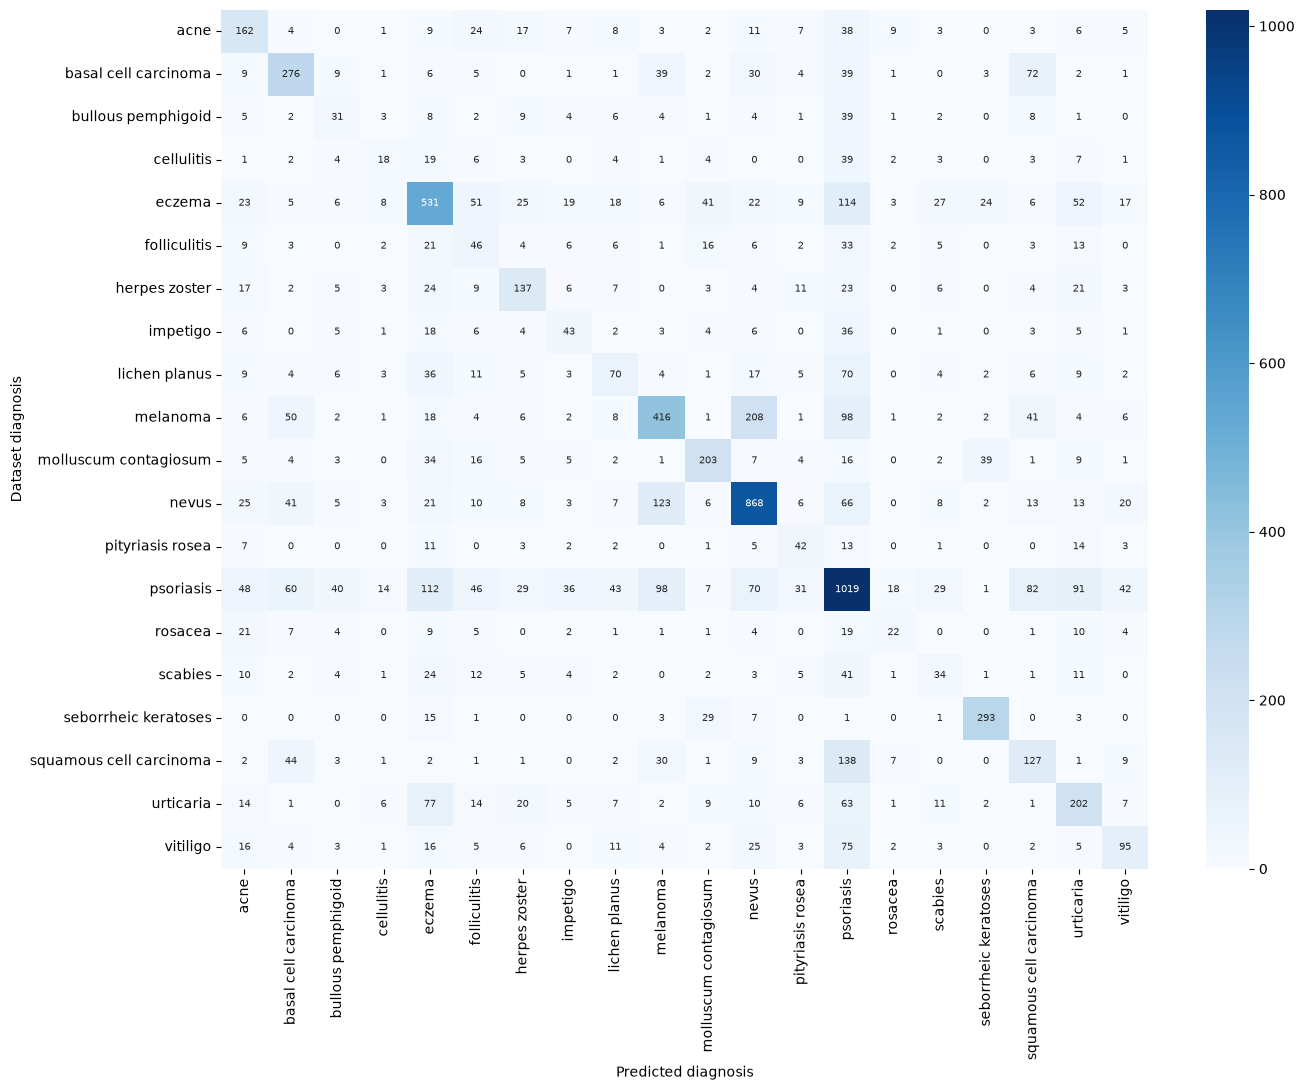

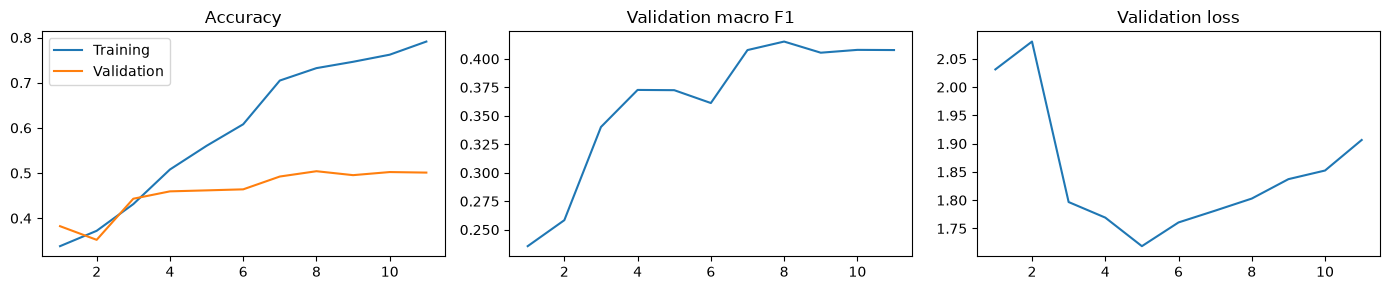

In [ ]:
checkpoint = torch.load(model_filename, map_location=device, weights_only=True)
assert checkpoint["classes"] == class_names
model.load_state_dict(checkpoint["weights"])
actual, predicted, validation_loss = evaluate_model(model, full_validation_loader)
print("Best epoch:", checkpoint["epoch"])
print("Full validation accuracy:", accuracy_score(actual, predicted))
print("Full validation macro F1:", f1_score(actual, predicted, labels=range(len(class_names)), average="macro", zero_division=0))
print("Full validation loss:", validation_loss)

report = classification_report(actual, predicted, labels=range(len(class_names)), target_names=class_names, output_dict=True, zero_division=0)
report_table = pd.DataFrame(report).T.drop(index="accuracy", errors="ignore")
report_table.to_csv(run_name + "_report.csv")
print(report_table)

predictions = full_validation_data.copy()
predictions["predicted_label"] = [class_names[number] for number in predicted]
predictions["correct"] = predictions["label"] == predictions["predicted_label"]
predictions.to_csv(run_name + "_validation_predictions.csv", index=False)
predictions[~predictions["correct"]].to_csv(run_name + "_mistakes.csv", index=False)
print(predictions.groupby("source")["correct"].agg(["count", "mean"]))
predictions.groupby(["source", "label"])["correct"].agg(["count", "mean"]).to_csv(run_name + "_source_scores.csv")

matrix = confusion_matrix(actual, predicted, labels=range(len(class_names)))
plt.figure(figsize=(14, 11))
sns.heatmap(matrix, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names, annot_kws={"fontsize": 7})
plt.xlabel("Predicted diagnosis")
plt.ylabel("Dataset diagnosis")
plt.tight_layout()
plt.show()

history_table = pd.DataFrame(history)
figure, axes = plt.subplots(1, 3, figsize=(14, 3))
axes[0].plot(history_table["epoch"], history_table["training_accuracy"], label="Training")
axes[0].plot(history_table["epoch"], history_table["validation_accuracy"], label="Validation")
axes[0].set_title("Accuracy")
axes[0].legend()
axes[1].plot(history_table["epoch"], history_table["macro_f1"])
axes[1].set_title("Validation macro F1")
axes[2].plot(history_table["epoch"], history_table["validation_loss"])
axes[2].set_title("Validation loss")
plt.tight_layout()
plt.show()

## 16. Optional: predict the official images

The official CSV has no diagnosis labels. Keep one output row per input image,
including an image status if it could not be checked. Probabilities only compare
the 20 known classes; they are not calibrated medical confidence.


In [ ]:
if predict_official_images:
    official_results = official_data.copy()
    official_results["image_status"] = official_checks["status"].to_numpy()
    official_results["predicted_label"] = pd.Series([None] * len(official_results), dtype="object")
    official_results["probability"] = np.nan
    model.eval()
    with torch.no_grad():
        for start in tqdm(range(0, len(official_results), batch_size), desc="Official predictions"):
            batch = official_results.iloc[start:start + batch_size]
            batch = batch[batch["image_status"] == "ok"]
            if len(batch) == 0:
                continue
            images = torch.stack([validation_transform(load_image(name)) for name in batch["filename"]]).to(device)
            probabilities = model(images).softmax(dim=1)
            values, numbers = probabilities.max(dim=1)
            official_results.loc[batch.index, "predicted_label"] = [class_names[number] for number in numbers.cpu().tolist()]
            official_results.loc[batch.index, "probability"] = values.cpu().numpy()
    official_results.to_csv(run_name + "_official_predictions.csv", index=False)
    print("Official rows saved:", len(official_results))

Official predictions:   0%|          | 0/307 [00:00<?, ?it/s]

Official rows saved: 9806


## 17. Optional: predict one image

Enter an image filename to see the five highest-scoring known classes.


In [ ]:
new_image_filename = ""
if new_image_filename:
    image = validation_transform(load_image(new_image_filename)).unsqueeze(0).to(device)
    model.eval()
    with torch.no_grad():
        probabilities = model(image).softmax(dim=1)[0]
    values, numbers = probabilities.topk(min(5, len(class_names)))
    print(pd.DataFrame({"diagnosis": [class_names[number] for number in numbers.cpu().tolist()],
                        "probability": values.cpu().tolist()}))